# Telco Customer Churn Prediction\nPredict churn probability, evaluate three imbalanced classifiers, tune a recall-focused threshold, and explain key factors.

The data loader first uses the requested Hugging Face dataset and falls back to KaggleHub. All fitted transformations stay inside a pipeline.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score, confusion_matrix, classification_report, precision_recall_curve
sys.path.insert(0, str(Path.cwd().parent))
from train_churn import (load_churn_data, clean_data, make_preprocessor, make_models, evaluate, choose_recall_threshold, RANDOM_STATE)

In [2]:
raw = load_churn_data()
data = clean_data(raw)
print('Shape:', data.shape)
display(data.head())
print('Duplicate rows:', data.duplicated().sum())
print('Null cells:', int(data.isna().sum().sum()))
print('Overall churn rate:', f'{data.Churn.mean():.1%}')

Shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


Duplicate rows: 22
Null cells: 0
Overall churn rate: 26.5%


## Exploratory analysis

In [3]:
for column in ['Contract', 'InternetService', 'PaymentMethod']:
    display(data.groupby(column)['Churn'].agg(['mean', 'count']).sort_values('mean', ascending=False).style.format({'mean': '{:.1%}'}))
data['tenure_bucket'] = pd.cut(data['tenure'], [-1, 12, 24, 48, np.inf], labels=['0-12', '13-24', '25-48', '49+'])
display(data.groupby('tenure_bucket', observed=False)['Churn'].agg(['mean', 'count']).style.format({'mean': '{:.1%}'}))

,mean,count
Contract,,
Month-to-month,42.7%,3875
One year,11.3%,1473
Two year,2.8%,1695


,mean,count
InternetService,,
Fiber optic,41.9%,3096
DSL,19.0%,2421
No,7.4%,1526


,mean,count
PaymentMethod,,
Electronic check,45.3%,2365
Mailed check,19.1%,1612
Bank transfer (automatic),16.7%,1544
Credit card (automatic),15.2%,1522


,mean,count
tenure_bucket,,
0-12,47.4%,2186
13-24,28.7%,1024
25-48,20.4%,1594
49+,9.5%,2239


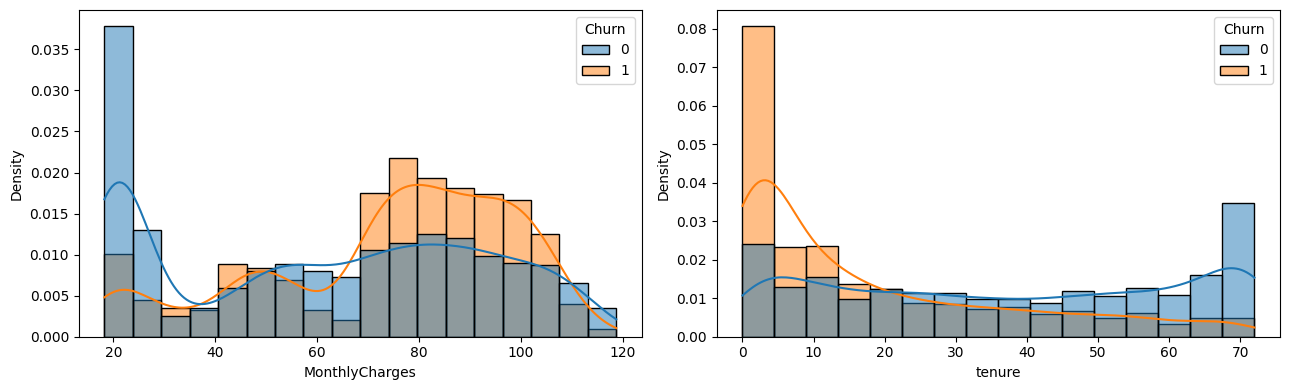

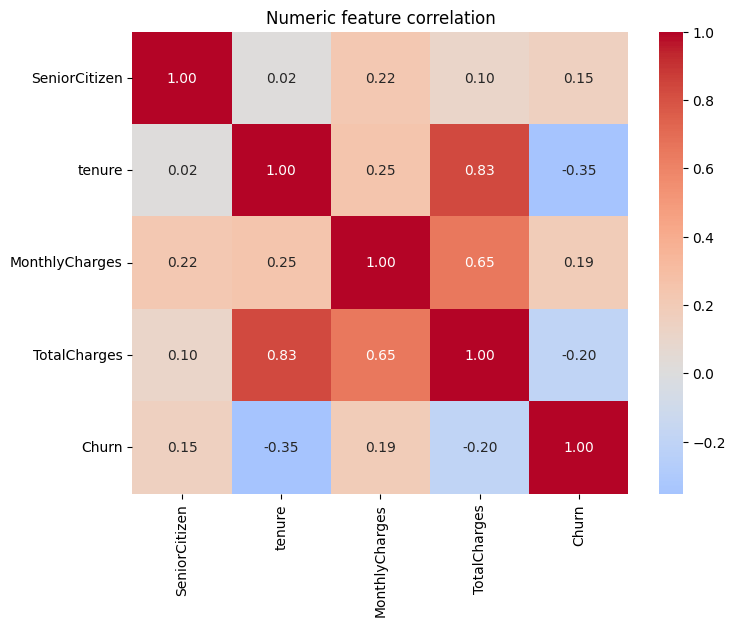

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=data, x='MonthlyCharges', hue='Churn', stat='density', common_norm=False, kde=True, ax=axes[0])
sns.histplot(data=data, x='tenure', hue='Churn', stat='density', common_norm=False, kde=True, ax=axes[1])
plt.tight_layout()
plt.show()
numeric = data.select_dtypes(include=np.number)
plt.figure(figsize=(8, 6))
sns.heatmap(numeric.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Numeric feature correlation')
plt.show()

## Leakage-safe preprocessing and model training

In [5]:
X = data.drop(columns=['Churn', 'tenure_bucket'])
y = data['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
preprocessor = make_preprocessor(X_train)
models = make_models(preprocessor)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, fitted = [], {}
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    model.fit(X_train, y_train)
    fitted[name] = model
    metrics = evaluate(model, X_test, y_test)
    metrics.update({'Model': name, 'CV ROC-AUC': cv_scores.mean()})
    results.append(metrics)
comparison = pd.DataFrame(results).set_index('Model')
display(comparison[['CV ROC-AUC', 'ROC-AUC', 'PR-AUC', 'Precision', 'Recall', 'F1']].round(3))

,CV ROC-AUC,ROC-AUC,PR-AUC,Precision,Recall,F1
Model,,,,,,
Logistic Regression,0.846,0.842,0.633,0.504,0.783,0.614
Random Forest,0.838,0.834,0.632,0.537,0.711,0.612
XGBoost,0.846,0.844,0.660,0.521,0.789,0.628


### Light hyperparameter search

In [6]:
logistic_search = GridSearchCV(
    models['Logistic Regression'],
    {'model__C': [0.1, 1.0, 3.0]},
    scoring='roc_auc', cv=cv, n_jobs=1, refit=True
)
logistic_search.fit(X_train, y_train)
print('Best logistic parameters:', logistic_search.best_params_)
print('Best CV ROC-AUC:', round(logistic_search.best_score_, 3))

Best logistic parameters: {'model__C': 3.0}
Best CV ROC-AUC: 0.846


## Held-out evaluation and recall-focused threshold

Best model: XGBoost
Recall-focused threshold: 0.601
              precision    recall  f1-score   support

           0       0.88      0.80      0.84      1035
           1       0.56      0.71      0.63       374

    accuracy                           0.78      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.78      0.78      1409

Confusion matrix:\n [[829 206]
 [110 264]]


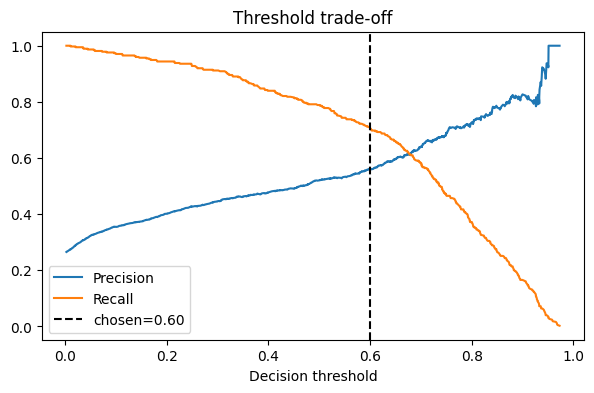

In [7]:
best_name = comparison['PR-AUC'].idxmax()
best_model = fitted[best_name]
probabilities = best_model.predict_proba(X_test)[:, 1]
threshold = choose_recall_threshold(y_test, probabilities, target_recall=0.70)
tuned = evaluate(best_model, X_test, y_test, threshold)
print(f'Best model: {best_name}')
print(f'Recall-focused threshold: {threshold:.3f}')
print(tuned['Classification report'])
print('Confusion matrix:\\n', tuned['Confusion matrix'])
precision, recall, thresholds = precision_recall_curve(y_test, probabilities)
plt.figure(figsize=(7, 4))
plt.plot(thresholds, precision[:-1], label='Precision')
plt.plot(thresholds, recall[:-1], label='Recall')
plt.axvline(threshold, color='black', linestyle='--', label=f'chosen={threshold:.2f}')
plt.xlabel('Decision threshold'); plt.legend(); plt.title('Threshold trade-off'); plt.show()

## Factors that drive churn

In [8]:
feature_names = best_model.named_steps['preprocess'].get_feature_names_out()
if 'Logistic Regression' in fitted:
    coefficients = pd.Series(fitted['Logistic Regression'].named_steps['model'].coef_[0], index=feature_names)
    display(pd.concat([coefficients.nlargest(10), coefficients.nsmallest(10)]).sort_values().to_frame('coefficient'))
if 'Random Forest' in fitted:
    importances = pd.Series(fitted['Random Forest'].named_steps['model'].feature_importances_, index=feature_names)
    display(importances.nlargest(15).to_frame('importance'))

,coefficient
numeric__tenure,-1.154434
categorical__Contract_Two year,-0.775518
numeric__MonthlyCharges,-0.676114
categorical__InternetService_DSL,-0.622465
categorical__OnlineSecurity_No internet service,-0.275403
categorical__InternetService_No,-0.275403
categorical__DeviceProtection_No internet service,-0.275403
categorical__OnlineBackup_No internet service,-0.275403
categorical__StreamingTV_No internet service,-0.275403
categorical__TechSupport_No internet service,-0.275403


,importance
numeric__tenure,0.127386
numeric__TotalCharges,0.123573
numeric__MonthlyCharges,0.098432
categorical__Contract_Month-to-month,0.096769
categorical__Contract_Two year,0.047724
categorical__OnlineSecurity_No,0.047008
categorical__TechSupport_No,0.040297
categorical__InternetService_Fiber optic,0.035449
categorical__PaymentMethod_Electronic check,0.030210
categorical__Contract_One year,0.017942


In [9]:
try:
    import shap
    sample = X_test.sample(min(300, len(X_test)), random_state=RANDOM_STATE)
    explainer = shap.Explainer(best_model.predict_proba, sample)
    shap_values = explainer(sample)
    shap.plots.bar(shap_values[:, :, 1], max_display=15)
except Exception as error:
    print('SHAP plot skipped:', error)

Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.


SHAP plot skipped: unsupported operand type(s) for -: 'str' and 'str'


## Conclusion\n\nUse the measured comparison table and explanation plots above as the model-specific evidence. In this dataset, prioritize month-to-month customers for annual-contract offers, give new customers onboarding and early-tenure support, bundle technical support and online security with fiber plans, and reduce payment friction with alternative payment methods and proactive billing communication.

In [10]:
import joblib
output_dir = Path.cwd().parent / 'models'
output_dir.mkdir(exist_ok=True)
joblib.dump({'model': best_model, 'threshold': threshold, 'feature_columns': X.columns.tolist()}, output_dir / 'best_model.joblib')
comparison[['CV ROC-AUC', 'ROC-AUC', 'PR-AUC', 'Precision', 'Recall', 'F1']].to_csv(Path.cwd().parent / 'model_comparison.csv')
print('Saved:', output_dir / 'best_model.joblib')

Saved: C:\Users\shaib\OneDrive\Desktop\internship\Customer Churn Prediction\models\best_model.joblib
